# Chapitre 1 - Exercices 1.1 à 1.6

Ce notebook traite les six premiers exercices du chapitre 1, centrés sur la charge et
la performance :

- **1.1** : ordres de grandeur du fan-out, seuil lectures/écritures et rattrapage
  d'un pic (calcul) ;
- **1.2** : où placer le seuil de l'approche hybride ? (calcul et mini-lab) ;
- **1.3** : percentiles à la main, et pourquoi on additionne des histogrammes
  (calcul) ;
- **1.4** : amplification de la latence de queue et requêtes de couverture (calcul et
  simulation) ;
- **1.5** : échantillonnage par réservoir contre histogramme pour estimer des
  percentiles en flux (mini-lab) ;
- **1.6** : loi de Little et dimensionnement d'un pool de connexions (calcul).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 1.1 : ordres de grandeur du fan-out

**Énoncé.** Un réseau social compte 50 millions d'utilisateurs actifs par jour. Chacun
publie en moyenne 2 messages et consulte sa timeline 30 fois par jour ; un compte suit en
moyenne 150 comptes.

1. Quel est le nombre moyen d'abonnés par compte ? Calculer les débits moyens de
   publications et de lectures de timeline (par seconde).
2. Calculer le nombre d'opérations élémentaires par seconde pour la timeline calculée à
   la lecture et pour la timeline matérialisée (fan-out à l'écriture).
3. Montrer que, dans ce modèle, le fan-out à l'écriture fait moins d'opérations que le
   calcul à la lecture **si et seulement si** on lit plus souvent qu'on ne publie.
4. Lors d'un événement, les publications sont multipliées par 10 pendant 20 minutes.
   L'infrastructure de fan-out a une capacité égale à **deux fois** le débit moyen
   d'écritures de fan-out, et les livraisons en retard sont mises en file d'attente.
   Quel retard maximal subit une livraison ? Combien de temps faut-il pour résorber la
   file ?

**Rappels.** Lecture : `lectures × abonnements` accès ; écriture :
`publications × abonnés` écritures et une lecture par consultation. Dans un graphe
fermé, abonnés moyens = abonnements moyens (cours 1, section 2, section *Describing Load*).

**Solution.**

*1.* Chaque arête « A suit B » compte un abonnement pour A et un abonné pour B : le
nombre moyen d'abonnés vaut donc aussi **150**. Débits : $P = 50 \cdot 10^6 \times 2 / 86\,400
\approx 1\,157$ publications/s et $R = 50 \cdot 10^6 \times 30 / 86\,400 \approx 17\,361$
lectures/s.

*2.* À la lecture : $P + R \times 150 \approx 1\,157 + 2\,604\,000 \approx 2{,}6$ millions
d'opérations/s. À l'écriture : $P \times 150 + R \approx 173\,600 + 17\,361 \approx 191\,000$
opérations/s, quatorze fois moins.

*3.* Avec $F$ abonnés (= abonnements) moyens : écriture $PF + R$, lecture $P + RF$.
$PF + R < P + RF \iff (F-1)(P - R) < 0 \iff R > P$ (pour $F > 1$). Le fan-out gagne dès
qu'on lit plus qu'on ne publie, quel que soit $F$ ; l'écart, lui, croît avec $F$.

*4.* Débit moyen de fan-out $D = 173\,600$ écritures/s, capacité $C = 2D$. Pendant le pic
(1 200 s), la demande vaut $10D$ : la file grossit de $8D$ par seconde, jusqu'à
$8D \times 1\,200 \approx 1{,}67 \cdot 10^9$ écritures. Une livraison déposée en dernier
attend que toute la file devant elle soit traitée, soit $1{,}67 \cdot 10^9 / C = 4\,800$ s
= **80 minutes** de retard. Après le pic, la file se vide à la vitesse $C - D = D$ :
$8D \times 1\,200 / D = 9\,600$ s, soit **2 h 40** pour revenir à la normale.

**Vérification numérique** : calcul direct, puis simulation seconde par seconde de la
file de fan-out (modèle fluide), avec le retard d'une livraison déposée à chaque instant.

P = 1157 publications/s ; R = 17361 lectures/s
à la lecture : 2 605 324 op/s ; à l'écriture : 190 972 op/s ; rapport 13.6


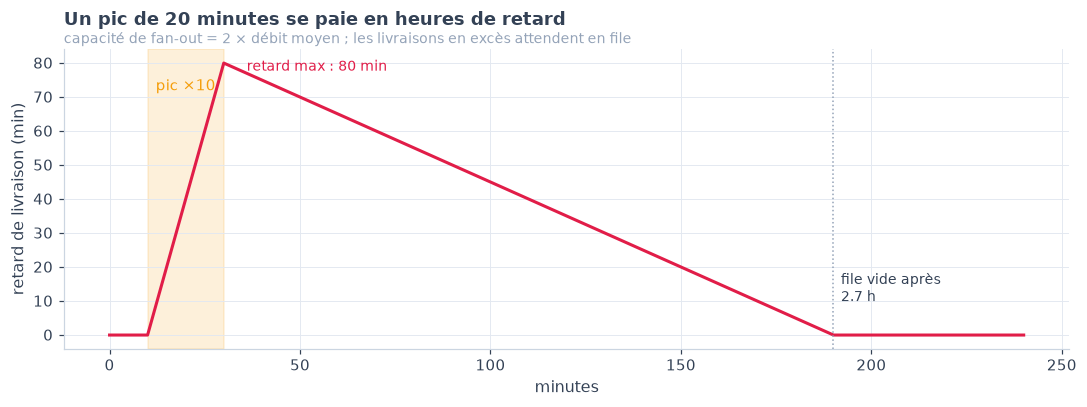

In [2]:
actifs, pub_j, lec_j, F = 50e6, 2, 30, 150
P, R = actifs * pub_j / 86400, actifs * lec_j / 86400
print(f"P = {P:.0f} publications/s ; R = {R:.0f} lectures/s")
print(f"à la lecture : {fmt(P + R * F)} op/s ; à l'écriture : {fmt(P * F + R)} op/s ; rapport {(P + R * F) / (P * F + R):.1f}")

D = P * F
C = 2 * D
T = 4 * 3600
t = np.arange(T)
demande = np.where((t >= 600) & (t < 1800), 10 * D, D)
file = np.zeros(T)
for s in range(1, T):
    file[s] = max(0.0, file[s - 1] + demande[s] - C)
retard = file / C                                   # FIFO : temps pour écouler la file devant soi
fin = t[(t > 1800) & (file == 0)][0]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t / 60, retard / 60, color=ROSE, lw=2)
ax.axvspan(10, 30, color=AMBER, alpha=0.15); ax.text(20, retard.max() / 60 * 0.9, "pic ×10", ha="center", color=AMBER)
ax.annotate(f"retard max : {retard.max() / 60:.0f} min", (30, retard.max() / 60), (15, -5), textcoords="offset points",
            fontsize=9, color=ROSE)
ax.axvline(fin / 60, color=GRAY, ls=":", lw=1)
ax.text(fin / 60 + 2, 10, f"file vide après\n{(fin - 1800) / 3600:.1f} h", fontsize=9, color=SLATE)
ax.set_xlabel("minutes"); ax.set_ylabel("retard de livraison (min)")
ax.set_title("Un pic de 20 minutes se paie en heures de retard")
subtitle(ax, "capacité de fan-out = 2 × débit moyen ; les livraisons en excès attendent en file")
plt.tight_layout(); plt.show()

La simulation retrouve les 80 minutes de retard et les 2 h 40 de rattrapage. Les lectures
restent rapides pendant tout ce temps (on sert des timelines un peu périmées depuis le
cache), mais un message publié au pic de l'événement n'atteint ses abonnés qu'une heure
et demie plus tard : c'est le prix d'une capacité dimensionnée pour la moyenne.

> **À retenir.** Le fan-out à l'écriture gagne dès que les lectures sont plus fréquentes
> que les écritures. Un pic d'écritures peut être absorbé par une file, mais le retard
> accumulé vaut (excès × durée) / capacité, et le rattrapage dépend de la marge
> capacité - débit moyen.